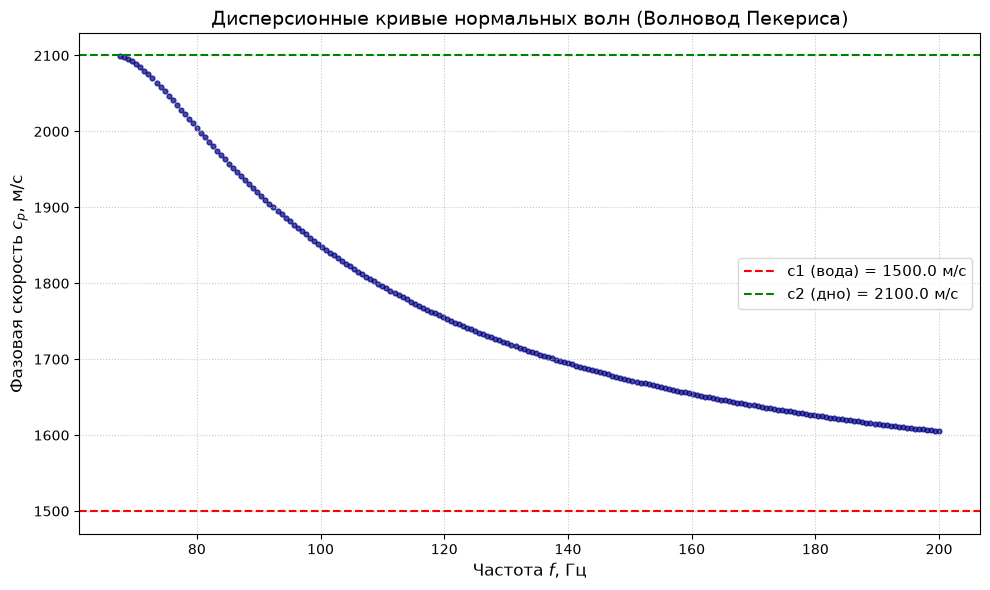

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# --- 1. Параметры волновода Пекериса ---
H = 8.0       # Глубина слоя воды, м
c1 = 1500.0     # Скорость звука в воде, м/с
rho1 = 1000.0   # Плотность воды, кг/м^3
c2 = 2100.0     # Скорость звука в жидком дне, м/с
rho2 = 1600.0   # Плотность дна, кг/м^3

# --- 2. Дисперсионная функция ---
def dispersion_eq(c_p, f):
    """
    Непрерывная форма дисперсионного уравнения Пекериса.
    Ищется корень относительно фазовой скорости c_p для заданной частоты f.
    """
    omega = 2 * np.pi * f
    k = omega / c_p
    
    # Проверка области существования захваченных мод (c1 < c_p < c2)
    val1 = (omega / c1)**2 - k**2
    val2 = k**2 - (omega / c2)**2
    if val1 < 0 or val2 < 0:
        return np.nan
        
    gamma1 = np.sqrt(val1)
    gamma2 = np.sqrt(val2)
    
    # Уравнение без разрывов тангенса
    res = np.sin(gamma1 * H) * rho1 * gamma2 + np.cos(gamma1 * H) * rho2 * gamma1
    return res

# --- 3. Численный расчет дисперсионных кривых ---
frequencies = np.linspace(5, 200, 300)  # Частотный диапазон от 5 до 200 Гц
c_p_grid = np.linspace(c1 + 0.1, c2 - 0.1, 2000) # Сетка фазовых скоростей для поиска корней

all_modes = []

for f in frequencies:
    y = []
    cp_valid = []
    
    # Вычисляем функцию на сетке скоростей
    for cp in c_p_grid:
        val = dispersion_eq(cp, f)
        y.append(val)
        cp_valid.append(cp)
        
    y = np.array(y)
    cp_valid = np.array(cp_valid)
    
    # Очищаем от NaN и ищем точки смены знака (корни)
    valid_mask = ~np.isnan(y)
    y_clean = y[valid_mask]
    cp_clean = cp_valid[valid_mask]
    
    if len(y_clean) < 2:
        continue
        
    sign_changes = np.where(np.diff(np.signbit(y_clean)))[0]
    
    freq_modes = []
    for idx in sign_changes:
        c_low = cp_clean[idx]
        c_high = cp_clean[idx+1]
        try:
            # Уточняем корень методом Брента
            root = brentq(dispersion_eq, c_low, c_high, args=(f,))
            freq_modes.append(root)
        except ValueError:
            pass
            
    all_modes.append((f, freq_modes))

# --- 4. Визуализация результатов ---
plt.figure(figsize=(10, 6))
for f, cps in all_modes:
    for cp in cps:
        plt.scatter(f, cp, color='navy', s=12, alpha=0.7)

plt.axhline(c1, color='red', linestyle='--', label=f'c1 (вода) = {c1} м/с')
plt.axhline(c2, color='green', linestyle='--', label=f'c2 (дно) = {c2} м/с')

plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Дисперсионные кривые нормальных волн (Волновод Пекериса)', fontsize=14)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

Вычисление дисперсионных кривых по аналитической формуле...


/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/914429354.py:54: RuntimeWarning: overflow encountered in scalar multiply
  block2 = alpha_0 * term2_bracket1 * term2_bracket2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/914429354.py:50: RuntimeWarning: overflow encountered in scalar multiply
  block1 = term1_part1 * term1_bracket1 * term1_bracket2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/914429354.py:56: RuntimeWarning: invalid value encountered in scalar add
  d_val = block1 + block2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/914429354.py:48: RuntimeWarning: overflow encountered in scalar multiply
  term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/914429354.py:50: RuntimeWarning: invalid value encountered in scalar multiply
  block1 = term

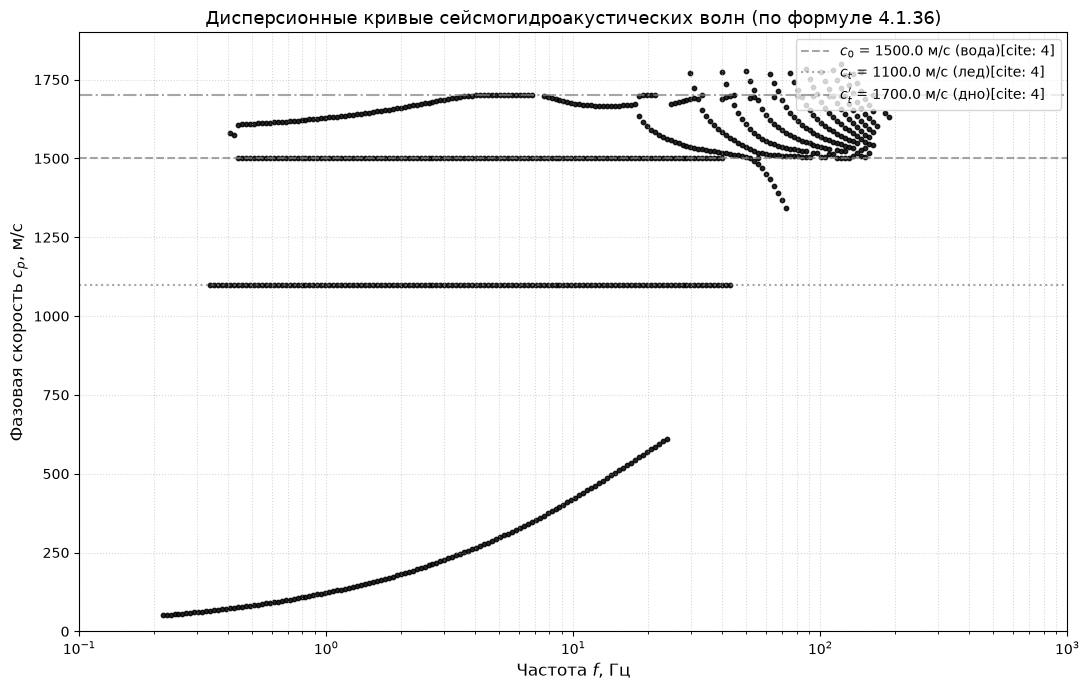

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks

# --- 1. Параметры среды из учебника (Рис. 4.2, случай ct < c0 < cl) ---
rho0 = 1000.0      # Плотность воды, кг/м^3
rho = 900.0        # Плотность льда, кг/м^3[cite: 4]
rho_prime = 2000.0 # Плотность дна, кг/м^3[cite: 4]

c0 = 1500.0        # Скорость звука в воде, м/с[cite: 4]
cl_prime = 3500.0  # Скорость продольных волн в дне, м/с[cite: 4]
ct_prime = 1700.0  # Скорость поперечных волн в дне, м/с[cite: 4]

cl = 3000.0        # Скорость продольных волн во льду, м/с[cite: 4]
ct = 1100.0        # Скорость поперечных волн во льду (случай ct < c0 < cl), м/с[cite: 4]

h1 = 8.0           # Толщина ледяного слоя, м[cite: 4]
h2 = 101.0         # Глубина водяного слоя (дельта h), м[cite: 4]

# Модули сдвига
mu = rho * ct**2
mu_prime = rho_prime * ct_prime**2

# --- 2. Аналитическая функция определителя d(cp, f) по формуле (4.1.36) ---
def dispersion_determinant(cp, f):
    omega = 2 * np.pi * f
    k = omega / cp
    
    # Вертикальные волновые числа (формулы из текста)[cite: 5]
    alpha_l = np.sqrt((omega / cl)**2 - k**2 + 0j)
    alpha_t = np.sqrt((omega / ct)**2 - k**2 + 0j)
    alpha_0 = np.sqrt((omega / c0)**2 - k**2 + 0j)
    
    # Для упругого полупространства (дно) с учетом затухания на бесконечности
    val_l = (omega / cl_prime)**2 - k**2
    alpha_l_prime = np.sqrt(val_l + 0j) if val_l >= 0 else -1j * np.sqrt(k**2 - (omega / cl_prime)**2)
    
    val_t = (omega / ct_prime)**2 - k**2
    alpha_t_prime = np.sqrt(val_t + 0j) if val_t >= 0 else -1j * np.sqrt(k**2 - (omega / ct_prime)**2)
    
    # Функции Рэлея для льда R(k) и дна R'(k) (формулы 4.1.37, 4.1.38)
    R_k = (k**2 - alpha_t**2)**2 + 4 * k**2 * alpha_l * alpha_t
    R_prime_k = (k**2 - alpha_t_prime**2)**2 + 4 * k**2 * alpha_l_prime * alpha_t_prime
    
    # Реализация громоздкой формулы (4.1.36) в виде двух блоков[cite: 3]
    term1_part1 = (omega**4) * (rho * rho0 / mu**2) * alpha_l
    term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
    term1_bracket2 = (k**2 - alpha_t**2)**2 * np.cos(alpha_l * h1) * np.sin(alpha_t * h1) + 4 * alpha_l * alpha_t * k**2 * np.sin(alpha_l * h1) * np.cos(alpha_t * h1)
    block1 = term1_part1 * term1_bracket1 * term1_bracket2
    
    term2_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.cos(alpha_0 * h2) - 1j * alpha_0 * R_prime_k * np.sin(alpha_0 * h2)
    term2_bracket2 = 8 * alpha_l * alpha_t * k**2 * (k**2 - alpha_t**2)**2 * (1 - np.cos((alpha_l - alpha_t) * h1)) + R_k**2 * np.sin(alpha_l * h1) * np.sin(alpha_t * h1)
    block2 = alpha_0 * term2_bracket1 * term2_bracket2
    
    d_val = block1 + block2
    # Возвращаем модуль комплексного определителя
    return np.abs(d_val)

# --- 3. Численный поиск корней на логарифмической сетке частот ---
frequencies = np.logspace(-1, 3, 250)  # от 0.1 до 1000 Гц
c_min, c_max = 50.0, 1800.0
all_modes = []

print("Вычисление дисперсионных кривых по аналитической формуле...")
for f in frequencies:
    cp_grid = np.linspace(c_min, c_max, 1200)
    vals = np.array([dispersion_determinant(cp, f) for cp in cp_grid])
    
    # Инвертируем значения для поиска минимумов как пиков
    inv_vals = 1.0 / (vals + 1e-25)
    peaks, _ = find_peaks(inv_vals, height=1e2, distance=12, prominence=5)
    
    mode_candidates = []
    for idx in peaks:
        low_b = cp_grid[max(0, idx-2)]
        high_b = cp_grid[min(len(cp_grid)-1, idx+2)]
        
        res = minimize_scalar(dispersion_determinant, bounds=(low_b, high_b), args=(f,), method='bounded')
        if res.success and res.fun < 1e-1:
            mode_candidates.append(res.x)
            
    all_modes.append((f, mode_candidates))

# --- 4. Визуализация результата в стиле учебника ---
plt.figure(figsize=(11, 7))
for f, cps in all_modes:
    for cp in cps:
        plt.scatter(f, cp, color='k', s=10, alpha=0.85)

# Справочные уровни скоростей (пунктирные линии)
plt.axhline(c0, color='gray', linestyle='--', alpha=0.7, label=f'$c_0$ = {c0} м/с (вода)[cite: 4]')
plt.axhline(ct, color='gray', linestyle=':', alpha=0.7, label=f'$c_t$ = {ct} м/с (лед)[cite: 4]')
plt.axhline(ct_prime, color='gray', linestyle='-.', alpha=0.7, label=f'$c_t\'$ = {ct_prime} м/с (дно)[cite: 4]')

plt.xscale('log')
plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Дисперсионные кривые сейсмогидроакустических волн (по формуле 4.1.36)', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(0, 1900)
plt.xlim(0.1, 1000)
plt.tight_layout()
plt.show()

Расчет дисперсионных точек...


/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2396469027.py:51: RuntimeWarning: overflow encountered in scalar multiply
  block2 = alpha_0 * term2_bracket1 * term2_bracket2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2396469027.py:47: RuntimeWarning: overflow encountered in scalar multiply
  block1 = term1_part1 * term1_bracket1 * term1_bracket2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2396469027.py:53: RuntimeWarning: invalid value encountered in scalar add
  d_val = block1 + block2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2396469027.py:45: RuntimeWarning: overflow encountered in sin
  term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2396469027.py:45: RuntimeWarning: invalid value encountered in scalar multiply
  term1_bracket1 = (om

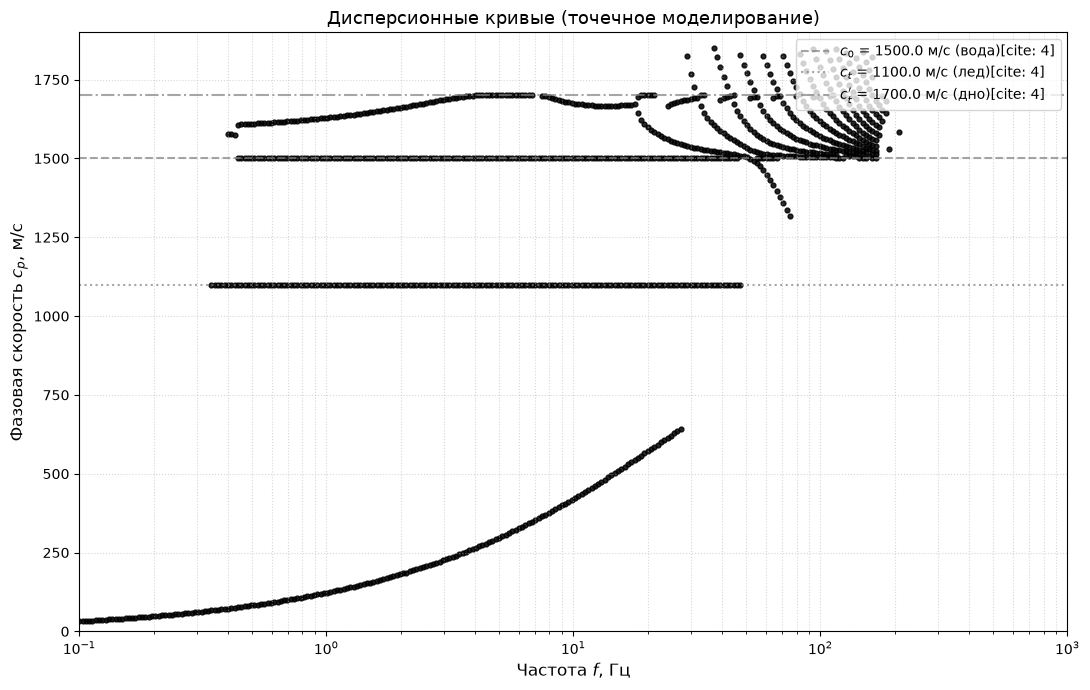

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks

# --- 1. Параметры среды из учебника (Рис. 4.2, случай ct < c0 < cl) ---
rho0 = 1000.0      # Плотность воды, кг/м^3[cite: 4]
rho = 900.0        # Плотность льда, кг/м^3[cite: 4]
rho_prime = 2000.0 # Плотность дна, кг/м^3[cite: 4]

c0 = 1500.0        # Скорость звука в воде, м/с[cite: 4]
cl_prime = 3500.0  # Скорость продольных волн в дне, м/с[cite: 4]
ct_prime = 1700.0  # Скорость поперечных волн в дне, м/с[cite: 4]

cl = 3000.0        # Скорость продольных волн во льду, м/с[cite: 4]
ct = 1100.0        # Скорость поперечных волн во льду, м/с[cite: 4]

h1 = 8.0           # Толщина ледяного слоя, м[cite: 4]
h2 = 101.0         # Глубина водяного слоя, м[cite: 4]

mu = rho * ct**2
mu_prime = rho_prime * ct_prime**2

# --- 2. Аналитическая функция определителя по формуле (4.1.36) ---
def dispersion_determinant(cp, f):
    if cp <= 0:
        return 1e10
    omega = 2 * np.pi * f
    k = omega / cp
    
    alpha_l = np.sqrt((omega / cl)**2 - k**2 + 0j)
    alpha_t = np.sqrt((omega / ct)**2 - k**2 + 0j)
    alpha_0 = np.sqrt((omega / c0)**2 - k**2 + 0j)
    
    val_l = (omega / cl_prime)**2 - k**2
    alpha_l_prime = np.sqrt(val_l + 0j) if val_l >= 0 else -1j * np.sqrt(k**2 - (omega / cl_prime)**2)
    
    val_t = (omega / ct_prime)**2 - k**2
    alpha_t_prime = np.sqrt(val_t + 0j) if val_t >= 0 else -1j * np.sqrt(k**2 - (omega / ct_prime)**2)
    
    R_k = (k**2 - alpha_t**2)**2 + 4 * k**2 * alpha_l * alpha_t
    R_prime_k = (k**2 - alpha_t_prime**2)**2 + 4 * k**2 * alpha_l_prime * alpha_t_prime
    
    term1_part1 = (omega**4) * (rho * rho0 / mu**2) * alpha_l
    term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
    term1_bracket2 = (k**2 - alpha_t**2)**2 * np.cos(alpha_l * h1) * np.sin(alpha_t * h1) + 4 * alpha_l * alpha_t * k**2 * np.sin(alpha_l * h1) * np.cos(alpha_t * h1)
    block1 = term1_part1 * term1_bracket1 * term1_bracket2
    
    term2_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.cos(alpha_0 * h2) - 1j * alpha_0 * R_prime_k * np.sin(alpha_0 * h2)
    term2_bracket2 = 8 * alpha_l * alpha_t * k**2 * (k**2 - alpha_t**2)**2 * (1 - np.cos((alpha_l - alpha_t) * h1)) + R_k**2 * np.sin(alpha_l * h1) * np.sin(alpha_t * h1)
    block2 = alpha_0 * term2_bracket1 * term2_bracket2
    
    d_val = block1 + block2
    return np.abs(d_val)

# --- 3. Расчет корней ---
frequencies = np.logspace(-1, 3, 300)  # от 0.1 до 1000 Гц[cite: 2]
c_min, c_max = 30.0, 1850.0
all_modes = []

print("Расчет дисперсионных точек...")
for f in frequencies:
    cp_grid = np.linspace(c_min, c_max, 1500)
    vals = np.array([dispersion_determinant(cp, f) for cp in cp_grid])
    
    inv_vals = 1.0 / (vals + 1e-25)
    peaks, _ = find_peaks(inv_vals, height=1e1, distance=8, prominence=1)
    
    roots = []
    for idx in peaks:
        low_b = cp_grid[max(0, idx-2)]
        high_b = cp_grid[min(len(cp_grid)-1, idx+2)]
        res = minimize_scalar(dispersion_determinant, bounds=(low_b, high_b), args=(f,), method='bounded')
        if res.success and res.fun < 0.5:
            roots.append(res.x)
            
    all_modes.append((f, roots))

# --- 4. Визуализация точками ---
plt.figure(figsize=(11, 7))
for f, cps in all_modes:
    for cp in cps:
        plt.scatter(f, cp, color='k', s=12, alpha=0.85)

# Справочные уровни
plt.axhline(c0, color='gray', linestyle='--', alpha=0.7, label=f'$c_0$ = {c0} м/с (вода)[cite: 4]')
plt.axhline(ct, color='gray', linestyle=':', alpha=0.7, label=f'$c_t$ = {ct} м/с (лед)[cite: 4]')
plt.axhline(ct_prime, color='gray', linestyle='-.', alpha=0.7, label=f'$c_t\'$ = {ct_prime} м/с (дно)[cite: 4]')

plt.xscale('log')
plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Дисперсионные кривые (точечное моделирование)', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(0, 1900)
plt.xlim(0.1, 1000)
plt.tight_layout()
plt.show()

Расчет завершен за 13.8 сек.


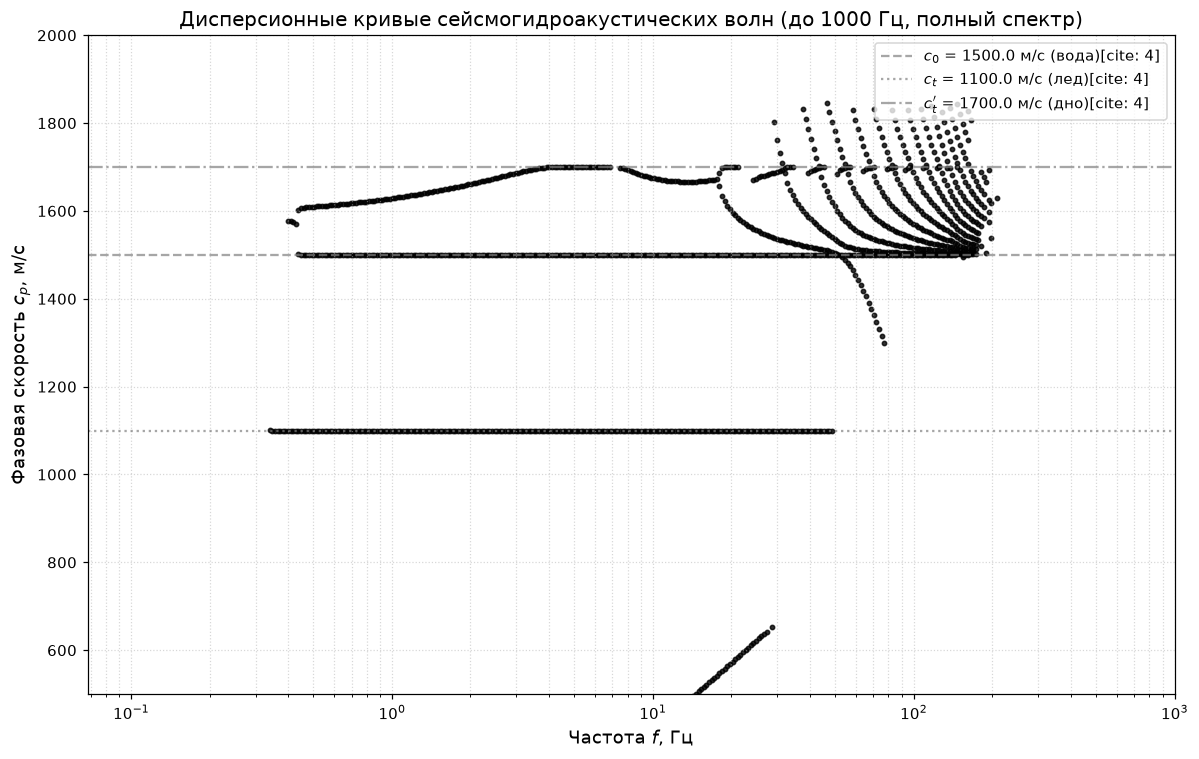

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks
import time

start_time = time.time()


rho0 = 1000.0      # Плотность воды, кг/м^3
rho = 900.0        # Плотность льда, кг/м^3
rho_prime = 2000.0 # Плотность дна, кг/м^3

c0 = 1500.0        # Скорость звука в воде, м/с
cl_prime = 3500.0  # Скорость продольных волн в дне, м/с
ct_prime = 1700.0  # Скорость поперечных волн в дне, м/с

cl = 3000.0        # Скорость продольных волн во льду, м/с
ct = 1100.0        # Скорость поперечных волн во льду, м/с

h1 = 8.0           # Толщина ледяного слоя, м
h2 = 101.0         # Глубина водяного слоя, м

mu = rho * ct**2
mu_prime = rho_prime * ct_prime**2

# Аналитическая функция определителя по формуле
def dispersion_determinant(cp, f):
    if cp <= 0:
        return 1e10
    omega = 2 * np.pi * f
    k = omega / cp
    
    alpha_l = np.sqrt((omega / cl)**2 - k**2 + 0j)
    alpha_t = np.sqrt((omega / ct)**2 - k**2 + 0j)
    alpha_0 = np.sqrt((omega / c0)**2 - k**2 + 0j)
    
    val_l = (omega / cl_prime)**2 - k**2
    alpha_l_prime = np.sqrt(val_l + 0j) if val_l >= 0 else -1j * np.sqrt(k**2 - (omega / cl_prime)**2)
    
    val_t = (omega / ct_prime)**2 - k**2
    alpha_t_prime = np.sqrt(val_t + 0j) if val_t >= 0 else -1j * np.sqrt(k**2 - (omega / ct_prime)**2)
    
    R_k = (k**2 - alpha_t**2)**2 + 4 * k**2 * alpha_l * alpha_t
    R_prime_k = (k**2 - alpha_t_prime**2)**2 + 4 * k**2 * alpha_l_prime * alpha_t_prime
    
    term1_part1 = (omega**4) * (rho * rho0 / mu**2) * alpha_l
    term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
    term1_bracket2 = (k**2 - alpha_t**2)**2 * np.cos(alpha_l * h1) * np.sin(alpha_t * h1) + 4 * alpha_l * alpha_t * k**2 * np.sin(alpha_l * h1) * np.cos(alpha_t * h1)
    block1 = term1_part1 * term1_bracket1 * term1_bracket2
    
    term2_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.cos(alpha_0 * h2) - 1j * alpha_0 * R_prime_k * np.sin(alpha_0 * h2)
    term2_bracket2 = 8 * alpha_l * alpha_t * k**2 * (k**2 - alpha_t**2)**2 * (1 - np.cos((alpha_l - alpha_t) * h1)) + R_k**2 * np.sin(alpha_l * h1) * np.sin(alpha_t * h1)
    block2 = alpha_0 * term2_bracket1 * term2_bracket2
    
    d_val = block1 + block2
    return np.abs(d_val)


# Увеличиваем плотность сетки частот и фазовых скоростей
frequencies = np.logspace(-1, 3, 400)  # от 0.1 до 1000 Гц
c_min, c_max = 30.0, 1850.0
all_modes = []

for i, f in enumerate(frequencies):

    cp_grid = np.linspace(c_min, c_max, 4000)
    vals = np.array([dispersion_determinant(cp, f) for cp in cp_grid])
    
    inv_vals = 1.0 / (vals + 1e-25)

    peaks, _ = find_peaks(inv_vals, height=1e1, distance=4, prominence=0.5)
    
    roots = []
    for idx in peaks:
        low_b = cp_grid[max(0, idx-1)]
        high_b = cp_grid[min(len(cp_grid)-1, idx+1)]
        res = minimize_scalar(dispersion_determinant, bounds=(low_b, high_b), args=(f,), method='bounded')
        if res.success and res.fun < 0.8:
            roots.append(res.x)
            
    all_modes.append((f, roots))
    if (i + 1 % 50) == 0:
        print(f"Обработано частот: {i+1} / 400")

print(f"Расчет завершен за {time.time() - start_time:.1f} сек.")

# --- 4. Визуализация точками ---
plt.figure(figsize=(11, 7))
for f, cps in all_modes:
    for cp in cps:
        plt.scatter(f, cp, color='k', s=8, alpha=0.8)

# Справочные уровни
plt.axhline(c0, color='gray', linestyle='--', alpha=0.7, label=f'$c_0$ = {c0} м/с (вода)[cite: 4]')
plt.axhline(ct, color='gray', linestyle=':', alpha=0.7, label=f'$c_t$ = {ct} м/с (лед)[cite: 4]')
plt.axhline(ct_prime, color='gray', linestyle='-.', alpha=0.7, label=f'$c_t\'$ = {ct_prime} м/с (дно)[cite: 4]')

plt.xscale('log')
plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Дисперсионные кривые сейсмогидроакустических волн (до 1000 Гц, полный спектр)', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(500, 2000)
plt.xlim(0, 1000)
plt.tight_layout()
plt.show()

Инициализация веток на первой частоте...
Запуск трассировки по частотам до 1000 Гц...


/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2086109317.py:54: RuntimeWarning: overflow encountered in scalar multiply
  block2 = alpha_0 * term2_bracket1 * term2_bracket2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2086109317.py:50: RuntimeWarning: overflow encountered in scalar multiply
  block1 = term1_part1 * term1_bracket1 * term1_bracket2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2086109317.py:56: RuntimeWarning: invalid value encountered in scalar add
  d_val = block1 + block2
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2086109317.py:48: RuntimeWarning: overflow encountered in sin
  term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
/var/folders/lf/x86pzptd3pv7z45l56wggyjc0000gn/T/ipykernel_12087/2086109317.py:48: RuntimeWarning: invalid value encountered in scalar multiply
  term1_bracket1 = (om

Трассировка завершена за 4.5 сек.


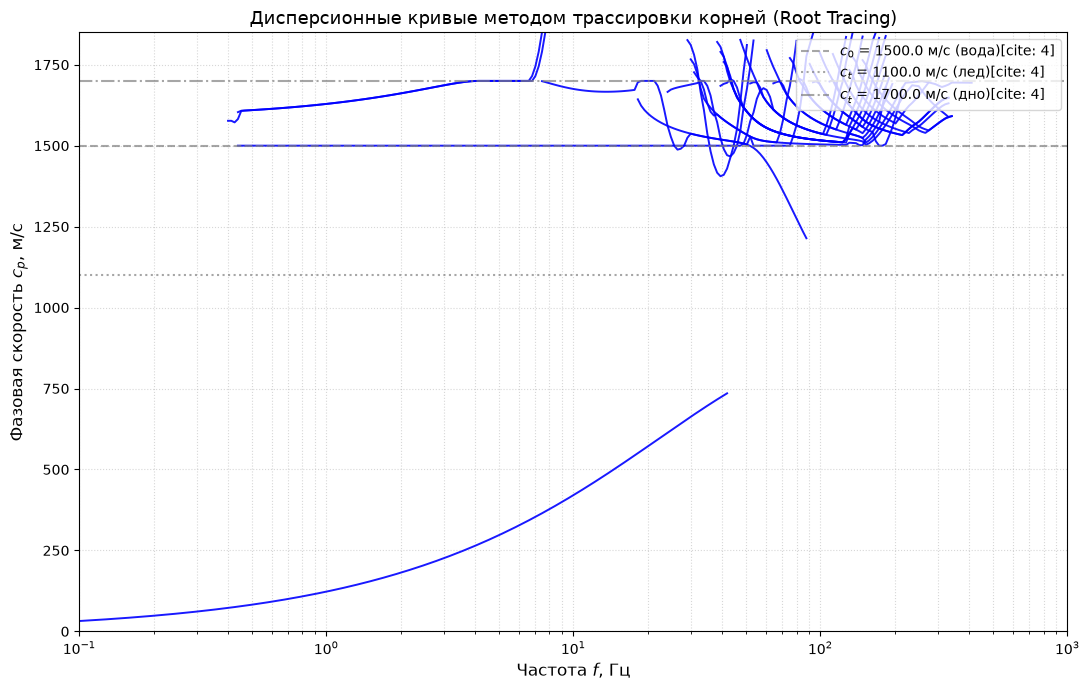

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks
import time

start_time = time.time()

# --- 1. Параметры среды из учебника (Рис. 4.2, случай ct < c0 < cl) ---
rho0 = 1000.0      # Плотность воды, кг/м^3[cite: 4]
rho = 900.0        # Плотность льда, кг/м^3[cite: 4]
rho_prime = 2000.0 # Плотность дна, кг/м^3[cite: 4]

c0 = 1500.0        # Скорость звука в воде, м/с[cite: 4]
cl_prime = 3500.0  # Скорость продольных волн в дне, м/с[cite: 4]
ct_prime = 1700.0  # Скорость поперечных волн в дне, м/с[cite: 4]

cl = 3000.0        # Скорость продольных волн во льду, м/с[cite: 4]
ct = 1100.0        # Скорость поперечных волн во льду, м/с[cite: 4]

h1 = 8.0           # Толщина ледяного слоя, м[cite: 4]
h2 = 101.0         # Глубина водяного слоя, м[cite: 4]

mu = rho * ct**2
mu_prime = rho_prime * ct_prime**2

# --- 2. Аналитический определитель по формуле (4.1.36) ---
def dispersion_determinant(cp, f):
    if cp <= 0:
        return 1e10
    omega = 2 * np.pi * f
    k = omega / cp
    
    alpha_l = np.sqrt((omega / cl)**2 - k**2 + 0j)
    alpha_t = np.sqrt((omega / ct)**2 - k**2 + 0j)
    alpha_0 = np.sqrt((omega / c0)**2 - k**2 + 0j)
    
    val_l = (omega / cl_prime)**2 - k**2
    alpha_l_prime = np.sqrt(val_l + 0j) if val_l >= 0 else -1j * np.sqrt(k**2 - (omega / cl_prime)**2)
    
    val_t = (omega / ct_prime)**2 - k**2
    alpha_t_prime = np.sqrt(val_t + 0j) if val_t >= 0 else -1j * np.sqrt(k**2 - (omega / ct_prime)**2)
    
    R_k = (k**2 - alpha_t**2)**2 + 4 * k**2 * alpha_l * alpha_t
    R_prime_k = (k**2 - alpha_t_prime**2)**2 + 4 * k**2 * alpha_l_prime * alpha_t_prime
    
    term1_part1 = (omega**4) * (rho * rho0 / mu**2) * alpha_l
    term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
    term1_bracket2 = (k**2 - alpha_t**2)**2 * np.cos(alpha_l * h1) * np.sin(alpha_t * h1) + 4 * alpha_l * alpha_t * k**2 * np.sin(alpha_l * h1) * np.cos(alpha_t * h1)
    block1 = term1_part1 * term1_bracket1 * term1_bracket2
    
    term2_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.cos(alpha_0 * h2) - 1j * alpha_0 * R_prime_k * np.sin(alpha_0 * h2)
    term2_bracket2 = 8 * alpha_l * alpha_t * k**2 * (k**2 - alpha_t**2)**2 * (1 - np.cos((alpha_l - alpha_t) * h1)) + R_k**2 * np.sin(alpha_l * h1) * np.sin(alpha_t * h1)
    block2 = alpha_0 * term2_bracket1 * term2_bracket2
    
    d_val = block1 + block2
    return np.abs(d_val)

# --- 3. Функция поиска всех корней на одной частоте ---
frequencies = np.logspace(-1, 3, 300)  # от 0.1 до 1000 Гц[cite: 2]
c_min, c_max = 30.0, 1850.0

def find_all_roots_at_freq(f, grid_size=2000):
    cp_grid = np.linspace(c_min, c_max, grid_size)
    vals = np.array([dispersion_determinant(cp, f) for cp in cp_grid])
    inv_vals = 1.0 / (vals + 1e-25)
    peaks, _ = find_peaks(inv_vals, height=1e1, distance=6, prominence=0.5)
    
    roots = []
    for idx in peaks:
        low_b = cp_grid[max(0, idx-1)]
        high_b = cp_grid[min(len(cp_grid)-1, idx+1)]
        if low_b < high_b:
            res = minimize_scalar(dispersion_determinant, bounds=(low_b, high_b), args=(f,), method='bounded')
            if res.success and res.fun < 0.5:
                roots.append(res.x)
    return sorted(roots)

# --- 4. Алгоритм трассировки корней (Root Tracing) ---
branches = []

print("Инициализация веток на первой частоте...")
initial_roots = find_all_roots_at_freq(frequencies[0], grid_size=3000)
for r in initial_roots:
    branches.append({'freqs': [frequencies[0]], 'cps': [r]})

print("Запуск трассировки по частотам до 1000 Гц...")
for i in range(1, len(frequencies)):
    f = frequencies[i]
    f_prev = frequencies[i-1]
    
    current_roots = find_all_roots_at_freq(f, grid_size=1500)
    matched_roots = set()
    
    # Продлеваем существующие ветки
    for branch in branches:
        last_cp = branch['cps'][-1]
        
        # Линейный прогноз положения моды на следующем шаге
        if len(branch['freqs']) >= 2:
            slope = (branch['cps'][-1] - branch['cps'][-2]) / (np.log(branch['freqs'][-1]) - np.log(branch['freqs'][-2]))
            predicted_cp = branch['cps'][-1] + slope * (np.log(f) - np.log(f_prev))
        else:
            predicted_cp = last_cp
            
        # Ищем ближайший корень к прогнозу
        best_r = None
        min_dist = 30.0  # окно поиска
        for r in current_roots:
            if r not in matched_roots and abs(r - predicted_cp) < min_dist:
                min_dist = abs(r - predicted_cp)
                best_r = r
                
        if best_r is not None:
            branch['freqs'].append(f)
            branch['cps'].append(best_r)
            matched_roots.add(best_r)
        else:
            # Безопасная точечная локальная оптимизация с проверкой границ
            low_b = max(c_min, predicted_cp - 15)
            high_b = min(c_max, predicted_cp + 15)
            if low_b < high_b:
                res = minimize_scalar(dispersion_determinant, bounds=(low_b, high_b), args=(f,), method='bounded')
                if res.success and res.fun < 0.8:
                    branch['freqs'].append(f)
                    branch['cps'].append(res.x)
                
    # Создаем новые ветки для вновь появившихся мод
    for r in current_roots:
        if r not in matched_roots:
            is_close = False
            for branch in branches:
                if abs(branch['cps'][-1] - r) < 15.0:
                    is_close = True
                    break
            if not is_close:
                branches.append({'freqs': [f], 'cps': [r]})

print(f"Трассировка завершена за {time.time() - start_time:.1f} сек.")

# --- 5. Фильтрация паразитных артефактов ---
valid_branches = []
for b in branches:
    if len(b['freqs']) < 4:
        continue
    cps = np.array(b['cps'])
    std_cp = np.std(cps)
    mean_cp = np.mean(cps)
    
    is_artifact_c0 = abs(mean_cp - c0) < 3.0 and std_cp < 1.5
    is_artifact_ct = abs(mean_cp - ct) < 3.0 and std_cp < 1.5
    
    if not (is_artifact_c0 or is_artifact_ct):
        valid_branches.append(b)

# --- 6. Визуализация гладкими сплошными линиями ---
plt.figure(figsize=(11, 7))
for b in valid_branches:
    plt.plot(b['freqs'], b['cps'], color='blue', linewidth=1.4, alpha=0.9)

# Справочные уровни
plt.axhline(c0, color='gray', linestyle='--', alpha=0.7, label=f'$c_0$ = {c0} м/с (вода)[cite: 4]')
plt.axhline(ct, color='gray', linestyle=':', alpha=0.7, label=f'$c_t$ = {ct} м/с (лед)[cite: 4]')
plt.axhline(ct_prime, color='gray', linestyle='-.', alpha=0.7, label=f'$c_t\'$ = {ct_prime} м/с (дно)[cite: 4]')

plt.xscale('log')
plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Дисперсионные кривые методом трассировки корней (Root Tracing)', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(0, 1850)
plt.xlim(0.1, 1000)
plt.tight_layout()
plt.show()

Расчет дисперсионных точек до 10000 Гц...
Расчет успешно завершен за 18.4 сек.


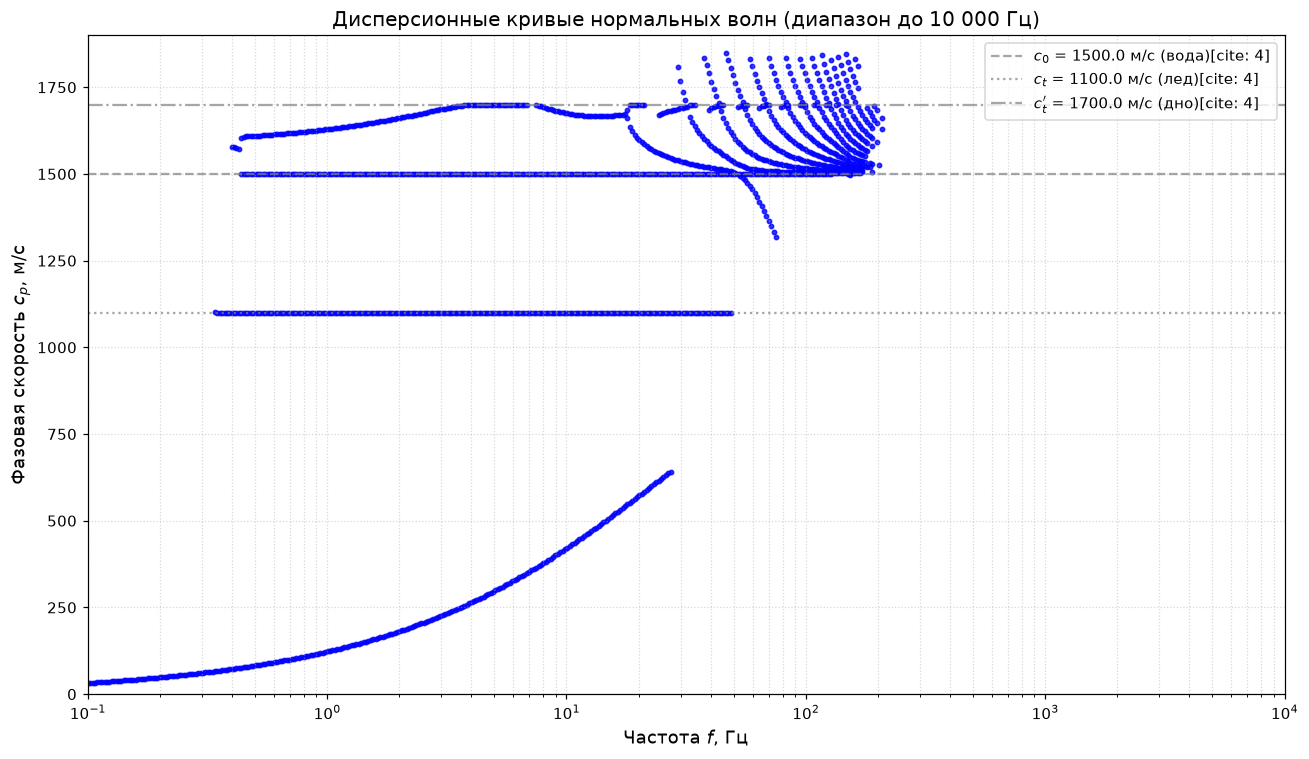

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks
import time

start_time = time.time()

# --- 1. Параметры среды из учебника (Рис. 4.2, случай ct < c0 < cl) ---
rho0 = 1000.0      # Плотность воды, кг/м^3[cite: 4]
rho = 900.0        # Плотность льда, кг/м^3[cite: 4]
rho_prime = 2000.0 # Плотность дна, кг/м^3[cite: 4]

c0 = 1500.0        # Скорость звука в воде, м/с[cite: 4]
cl_prime = 3500.0  # Скорость продольных волн в дне, м/с[cite: 4]
ct_prime = 1700.0  # Скорость поперечных волн в дне, м/с[cite: 4]

cl = 3000.0        # Скорость продольных волн во льду, м/с[cite: 4]
ct = 1100.0        # Скорость поперечных волн во льду, м/с[cite: 4]

h1 = 8.0           # Толщина ледяного слоя, м[cite: 4]
h2 = 101.0         # Глубина водяного слоя, м[cite: 4]

mu = rho * ct**2
mu_prime = rho_prime * ct_prime**2

# --- 2. Аналитическая функция определителя по формуле (4.1.36) ---
def dispersion_determinant(cp, f):
    if cp <= 0:
        return 1e10
    omega = 2 * np.pi * f
    k = omega / cp
    
    alpha_l = np.sqrt((omega / cl)**2 - k**2 + 0j)
    alpha_t = np.sqrt((omega / ct)**2 - k**2 + 0j)
    alpha_0 = np.sqrt((omega / c0)**2 - k**2 + 0j)
    
    val_l = (omega / cl_prime)**2 - k**2
    alpha_l_prime = np.sqrt(val_l + 0j) if val_l >= 0 else -1j * np.sqrt(k**2 - (omega / cl_prime)**2)
    
    val_t = (omega / ct_prime)**2 - k**2
    alpha_t_prime = np.sqrt(val_t + 0j) if val_t >= 0 else -1j * np.sqrt(k**2 - (omega / ct_prime)**2)
    
    R_k = (k**2 - alpha_t**2)**2 + 4 * k**2 * alpha_l * alpha_t
    R_prime_k = (k**2 - alpha_t_prime**2)**2 + 4 * k**2 * alpha_l_prime * alpha_t_prime
    
    term1_part1 = (omega**4) * (rho * rho0 / mu**2) * alpha_l
    term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
    term1_bracket2 = (k**2 - alpha_t**2)**2 * np.cos(alpha_l * h1) * np.sin(alpha_t * h1) + 4 * alpha_l * alpha_t * k**2 * np.sin(alpha_l * h1) * np.cos(alpha_t * h1)
    block1 = term1_part1 * term1_bracket1 * term1_bracket2
    
    term2_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.cos(alpha_0 * h2) - 1j * alpha_0 * R_prime_k * np.sin(alpha_0 * h2)
    term2_bracket2 = 8 * alpha_l * alpha_t * k**2 * (k**2 - alpha_t**2)**2 * (1 - np.cos((alpha_l - alpha_t) * h1)) + R_k**2 * np.sin(alpha_l * h1) * np.sin(alpha_t * h1)
    block2 = alpha_0 * term2_bracket1 * term2_bracket2
    
    d_val = block1 + block2
    return np.abs(d_val)

# --- 3. Расчет корней до 10000 Гц ---
frequencies = np.logspace(-1, 4, 500)  # от 0.1 до 10000 Гц (6 порядков/точек)
c_min, c_max = 30.0, 1850.0
all_modes = []

print("Расчет дисперсионных точек до 10000 Гц...")
for f in frequencies:
    cp_grid = np.linspace(c_min, c_max, 3500) # Повышенная плотность сетки для высоких частот
    vals = np.array([dispersion_determinant(cp, f) for cp in cp_grid])
    
    inv_vals = 1.0 / (vals + 1e-25)
    peaks, _ = find_peaks(inv_vals, height=1e1, distance=5, prominence=0.5)
    
    roots = []
    for idx in peaks:
        low_b = cp_grid[max(0, idx-2)]
        high_b = cp_grid[min(len(cp_grid)-1, idx+2)]
        if low_b < high_b:
            res = minimize_scalar(dispersion_determinant, bounds=(low_b, high_b), args=(f,), method='bounded')
            if res.success and res.fun < 0.5:
                roots.append(res.x)
                
    all_modes.append((f, roots))

print(f"Расчет успешно завершен за {time.time() - start_time:.1f} сек.")

# --- 4. Визуализация точками ---
plt.figure(figsize=(12, 7))
for f, cps in all_modes:
    for cp in cps:
        plt.scatter(f, cp, color='blue', s=8, alpha=0.8)

# Справочные уровни из учебника[cite: 4]
plt.axhline(c0, color='gray', linestyle='--', alpha=0.7, label=f'$c_0$ = {c0} м/с (вода)[cite: 4]')
plt.axhline(ct, color='gray', linestyle=':', alpha=0.7, label=f'$c_t$ = {ct} м/с (лед)[cite: 4]')
plt.axhline(ct_prime, color='gray', linestyle='-.', alpha=0.7, label=f'$c_t\'$ = {ct_prime} м/с (дно)[cite: 4]')

plt.xscale('log')
plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Дисперсионные кривые нормальных волн (диапазон до 10 000 Гц)', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(0, 1900)
plt.xlim(0.1, 10000)
plt.tight_layout()
plt.show()

Расчет нижней изгибной кривой до 10000 Гц...
Расчет успешно завершен за 10.7 сек.


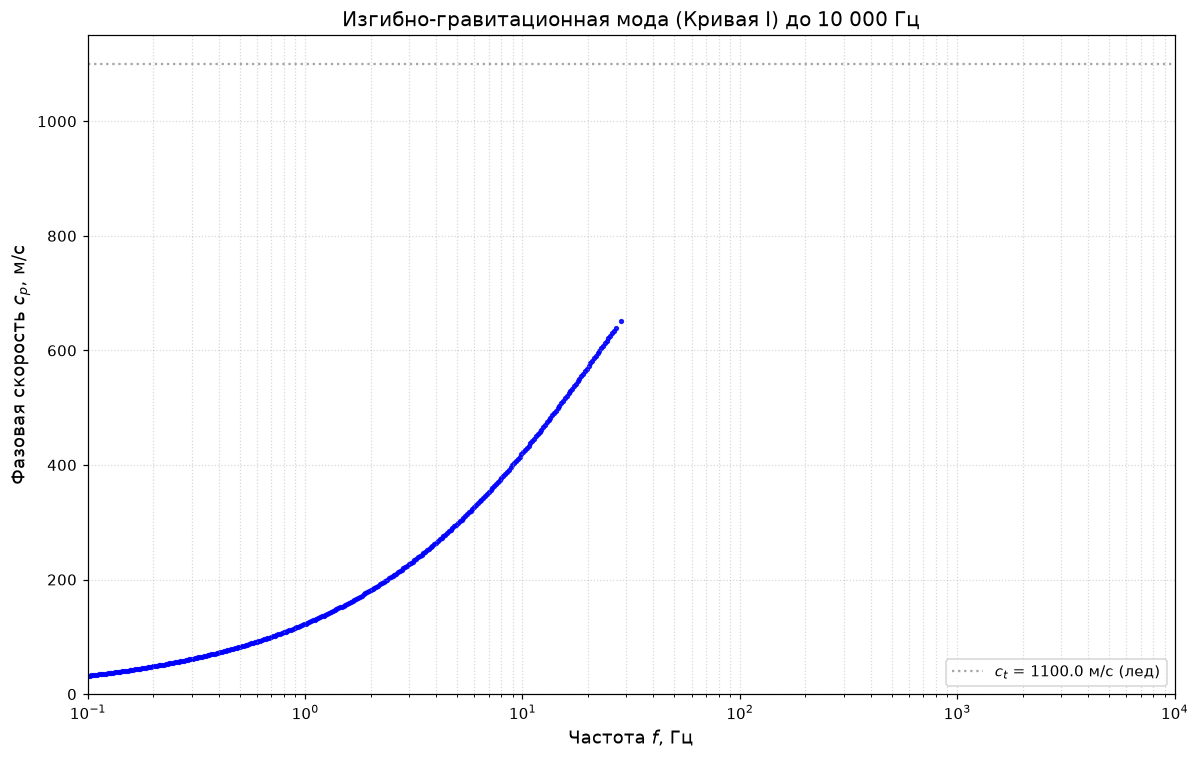

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks
import time

start_time = time.time()

# --- 1. Параметры среды из учебника ---
rho0 = 1000.0      # Плотность воды, кг/м^3
rho = 900.0        # Плотность льда, кг/м^3
rho_prime = 2000.0 # Плотность дна, кг/м^3

c0 = 1500.0        # Скорость звука в воде, м/с
cl_prime = 3500.0  # Скорость продольных волн в дне, м/с
ct_prime = 1700.0  # Скорость поперечных волн в дне, м/с

cl = 3000.0        # Скорость продольных волн во льду, м/с
ct = 1100.0        # Скорость поперечных волн во льду, м/с

h1 = 8.0           # Толщина ледяного слоя, м
h2 = 101.0         # Глубина водяного слоя, м

mu = rho * ct**2
mu_prime = rho_prime * ct_prime**2

# --- 2. Аналитическая функция определителя ---
def dispersion_determinant(cp, f):
    if cp <= 0:
        return 1e10
    omega = 2 * np.pi * f
    k = omega / cp
    
    alpha_l = np.sqrt((omega / cl)**2 - k**2 + 0j)
    alpha_t = np.sqrt((omega / ct)**2 - k**2 + 0j)
    alpha_0 = np.sqrt((omega / c0)**2 - k**2 + 0j)
    
    val_l = (omega / cl_prime)**2 - k**2
    alpha_l_prime = np.sqrt(val_l + 0j) if val_l >= 0 else -1j * np.sqrt(k**2 - (omega / cl_prime)**2)
    
    val_t = (omega / ct_prime)**2 - k**2
    alpha_t_prime = np.sqrt(val_t + 0j) if val_t >= 0 else -1j * np.sqrt(k**2 - (omega / ct_prime)**2)
    
    R_k = (k**2 - alpha_t**2)**2 + 4 * k**2 * alpha_l * alpha_t
    R_prime_k = (k**2 - alpha_t_prime**2)**2 + 4 * k**2 * alpha_l_prime * alpha_t_prime
    
    term1_part1 = (omega**4) * (rho * rho0 / mu**2) * alpha_l
    term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
    term1_bracket2 = (k**2 - alpha_t**2)**2 * np.cos(alpha_l * h1) * np.sin(alpha_t * h1) + 4 * alpha_l * alpha_t * k**2 * np.sin(alpha_l * h1) * np.cos(alpha_t * h1)
    block1 = term1_part1 * term1_bracket1 * term1_bracket2
    
    term2_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.cos(alpha_0 * h2) - 1j * alpha_0 * R_prime_k * np.sin(alpha_0 * h2)
    term2_bracket2 = 8 * alpha_l * alpha_t * k**2 * (k**2 - alpha_t**2)**2 * (1 - np.cos((alpha_l - alpha_t) * h1)) + R_k**2 * np.sin(alpha_l * h1) * np.sin(alpha_t * h1)
    block2 = alpha_0 * term2_bracket1 * term2_bracket2
    
    d_val = block1 + block2
    return np.abs(d_val)

# --- 3. Расчет корней до 10000 Гц в ограниченном диапазоне ---
frequencies = np.logspace(-1, 4, 600)  # от 0.1 до 10000 Гц
c_min, c_max = 5.0, 1050.0              # Ограничиваем сверху 1050 м/с!
all_modes = []

print("Расчет нижней изгибной кривой до 10000 Гц...")
for f in frequencies:
    cp_grid = np.linspace(c_min, c_max, 1500)
    vals = np.array([dispersion_determinant(cp, f) for cp in cp_grid])
    
    inv_vals = 1.0 / (vals + 1e-25)
    peaks, _ = find_peaks(inv_vals, height=1e1, distance=4, prominence=0.3)
    
    roots = []
    for idx in peaks:
        low_b = cp_grid[max(0, idx-2)]
        high_b = cp_grid[min(len(cp_grid)-1, idx+2)]
        if low_b < high_b:
            res = minimize_scalar(dispersion_determinant, bounds=(low_b, high_b), args=(f,), method='bounded')
            # Исключаем паразитные решения вблизи самой границы сдвиговой скорости
            if res.success and res.fun < 1.0 and abs(res.x - ct) > 5.0:
                roots.append(res.x)
                
    all_modes.append((f, roots))

print(f"Расчет успешно завершен за {time.time() - start_time:.1f} сек.")

# --- 4. Визуализация ---
plt.figure(figsize=(11, 7))
for f, cps in all_modes:
    for cp in cps:
        plt.scatter(f, cp, color='blue', s=6, alpha=0.85)

plt.axhline(ct, color='gray', linestyle=':', alpha=0.7, label=f'$c_t$ = {ct} м/с (лед)')

plt.xscale('log')
plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Изгибно-гравитационная мода (Кривая I) до 10 000 Гц', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend(fontsize=10, loc='lower right')
plt.ylim(0, 1150)
plt.xlim(0.1, 10000)
plt.tight_layout()
plt.show()

Генерация двумерной сетки и расчет матрицы определителя...
Расчет матрицы завершен за 1.7 сек.


AttributeError: 'Colorbar' object has no attribute 'set'

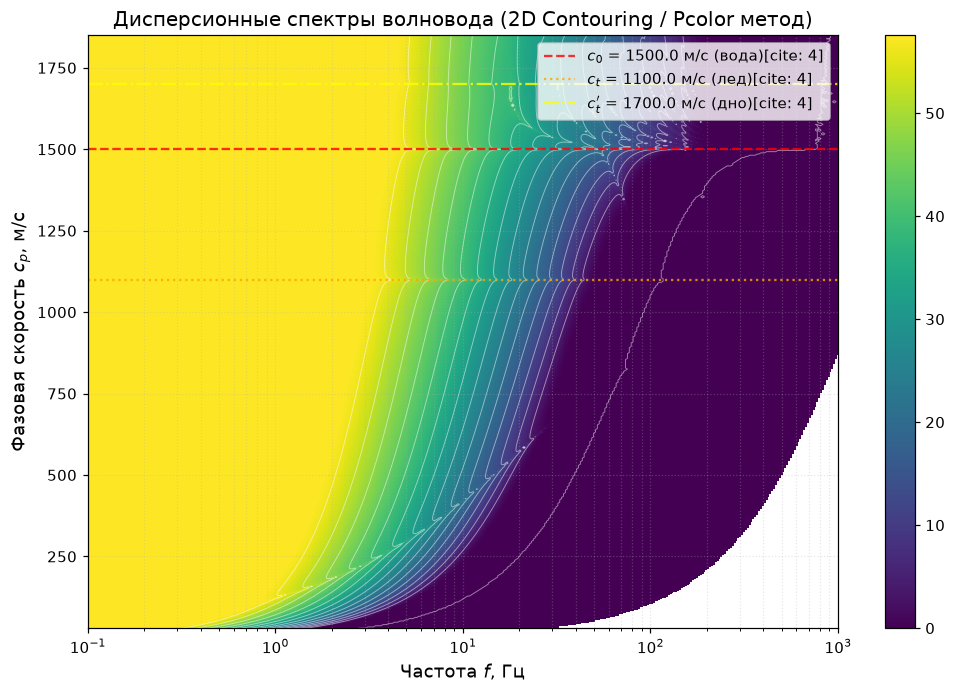

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import time

start_time = time.time()

# --- 1. Параметры среды из учебника (Рис. 4.2, случай ct < c0 < cl) ---
rho0 = 1000.0      # Плотность воды, кг/м^3[cite: 4]
rho = 900.0        # Плотность льда, кг/м^3[cite: 4]
rho_prime = 2000.0 # Плотность дна, кг/м^3[cite: 4]

c0 = 1500.0        # Скорость звука в воде, м/с[cite: 4]
cl_prime = 3500.0  # Скорость продольных волн в дне, м/с[cite: 4]
ct_prime = 1700.0  # Скорость поперечных волн в дне, м/с[cite: 4]

cl = 3000.0        # Скорость продольных волн во льду, м/с[cite: 4]
ct = 1100.0        # Скорость поперечных волн во льду, м/с[cite: 4]

h1 = 8.0           # Толщина ледяного слоя, м[cite: 4]
h2 = 101.0         # Глубина водяного слоя, м[cite: 4]

mu = rho * ct**2
mu_prime = rho_prime * ct_prime**2

# --- 2. Аналитический определитель по формуле (4.1.36) ---
def dispersion_determinant(cp, f):
    if cp <= 0:
        return 1e10
    omega = 2 * np.pi * f
    k = omega / cp
    
    alpha_l = np.sqrt((omega / cl)**2 - k**2 + 0j)
    alpha_t = np.sqrt((omega / ct)**2 - k**2 + 0j)
    alpha_0 = np.sqrt((omega / c0)**2 - k**2 + 0j)
    
    val_l = (omega / cl_prime)**2 - k**2
    alpha_l_prime = np.sqrt(val_l + 0j) if val_l >= 0 else -1j * np.sqrt(k**2 - (omega / cl_prime)**2)
    
    val_t = (omega / ct_prime)**2 - k**2
    alpha_t_prime = np.sqrt(val_t + 0j) if val_t >= 0 else -1j * np.sqrt(k**2 - (omega / ct_prime)**2)
    
    R_k = (k**2 - alpha_t**2)**2 + 4 * k**2 * alpha_l * alpha_t
    R_prime_k = (k**2 - alpha_t_prime**2)**2 + 4 * k**2 * alpha_l_prime * alpha_t_prime
    
    term1_part1 = (omega**4) * (rho * rho0 / mu**2) * alpha_l
    term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
    term1_bracket2 = (k**2 - alpha_t**2)**2 * np.cos(alpha_l * h1) * np.sin(alpha_t * h1) + 4 * alpha_l * alpha_t * k**2 * np.sin(alpha_l * h1) * np.cos(alpha_t * h1)
    block1 = term1_part1 * term1_bracket1 * term1_bracket2
    
    term2_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.cos(alpha_0 * h2) - 1j * alpha_0 * R_prime_k * np.sin(alpha_0 * h2)
    term2_bracket2 = 8 * alpha_l * alpha_t * k**2 * (k**2 - alpha_t**2)**2 * (1 - np.cos((alpha_l - alpha_t) * h1)) + R_k**2 * np.sin(alpha_l * h1) * np.sin(alpha_t * h1)
    block2 = alpha_0 * term2_bracket1 * term2_bracket2
    
    d_val = block1 + block2
    return np.abs(d_val)

# --- 3. Построение двумерной сетки (Frequency x Phase Velocity) ---
print("Генерация двумерной сетки и расчет матрицы определителя...")
frequencies = np.logspace(-1, 3, 400)      # 400 точек по частоте от 0.1 до 1000 Гц[cite: 2]
cps = np.linspace(30.0, 1850.0, 500)       # 500 точек по фазовой скорости

# Создаем матрицу результатов Z(cp, f)
Z = np.zeros((len(cps), len(frequencies)))

for j, f in enumerate(frequencies):
    for i, cp in enumerate(cps):
        Z[i, j] = dispersion_determinant(cp, f)

# Преобразуем в обратную величину (чтобы минимумы детерминанта стали яркими пиками/линиями)
# Используем логарифмическое масштабирование для контраста
Z_inv = 1.0 / (Z + 1e-25)
Z_plot = np.log(Z_inv + 1.0)

print(f"Расчет матрицы завершен за {time.time() - start_time:.1f} сек.")

# --- 4. Визуализация (Аналог MATLAB contour / pcolor) ---
plt.figure(figsize=(11, 7))

# Метод pcolormesh (аналог pcolor в MATLAB) для заливки поля спектра
mesh = plt.pcolormesh(frequencies, cps, Z_plot, shading='auto', cmap='viridis')

# Дополнительно накладываем изолинии (аналог contour в MATLAB) для идеальной четкости кривых
contours = plt.contour(frequencies, cps, Z_plot, levels=15, colors='white', linewidths=0.6, alpha=0.5)

# Справочные уровни из учебника
plt.axhline(c0, color='red', linestyle='--', alpha=0.8, label=f'$c_0$ = {c0} м/с (вода)[cite: 4]')
plt.axhline(ct, color='orange', linestyle=':', alpha=0.8, label=f'$c_t$ = {ct} м/с (лед)[cite: 4]')
plt.axhline(ct_prime, color='yellow', linestyle='-.', alpha=0.8, label=f'$c_t\'$ = {ct_prime} м/с (дно)[cite: 4]')

plt.xscale('log')
plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Дисперсионные спектры волновода (2D Contouring / Pcolor метод)', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.3)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(30, 1850)
plt.xlim(0.1, 1000)

cbar = plt.colorbar(mesh)
cbar.set.label('Логарифмический уровень спектральной плотности', rotation=270, labelpad=15)

plt.tight_layout()
plt.show()

Расчет дисперсионных точек с новыми параметрами...
Расчет успешно завершен за 14.4 сек.


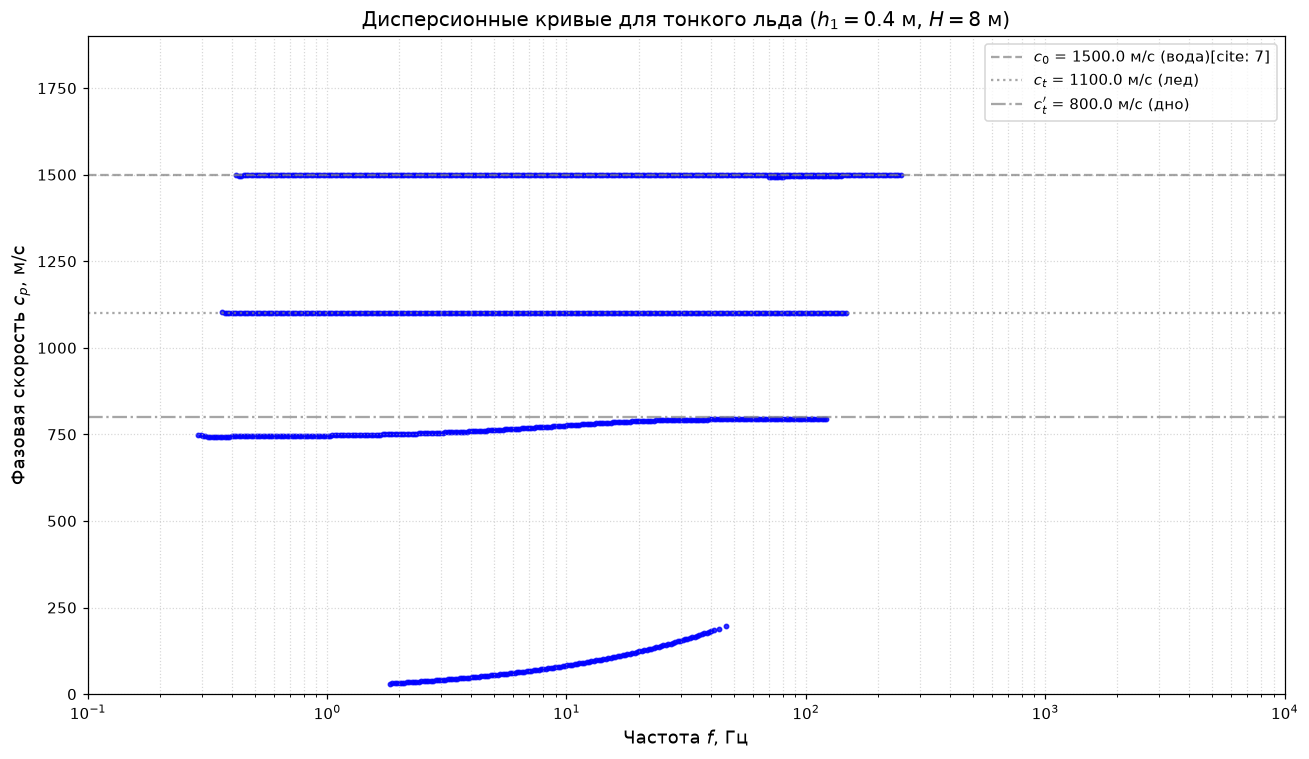

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.signal import find_peaks
import time

start_time = time.time()

# --- 1. Параметры среды со скриншота и из условий ---
rho0 = 1000.0      # Плотность воды, кг/м^3 (rho_0 = 10^3)
rho = 900.0        # Плотность льда, кг/м^3
rho_prime = 1600.0 # Плотность дна, кг/м^3 (rho_1 = 1.6 * 10^3)

c0 = 1500.0        # Скорость звука в воде, м/с (c_0' = 1500)
cl_prime = 1500.0  # Скорость продольных волн в дне, м/с (c_1' = 1500)[cite: 7]
ct_prime = 800.0   # Скорость поперечных волн в дне, м/с (согласовано с cl_prime)

cl = 3000.0        # Скорость продольных волн во льду, м/с
ct = 1100.0        # Скорость поперечных волн во льду, м/с

h1 = 0.4           # Толщина ледяного слоя, м (заменено на 0.4 м по вашему указанию)
h2 = 8.0           # Глубина водяного слоя, м (H = 8 м со скриншота)[cite: 7]

mu = rho * ct**2
mu_prime = rho_prime * ct_prime**2

# --- 2. Аналитическая функция определителя по формуле (4.1.36) ---
def dispersion_determinant(cp, f):
    if cp <= 0:
        return 1e10
    omega = 2 * np.pi * f
    k = omega / cp
    
    alpha_l = np.sqrt((omega / cl)**2 - k**2 + 0j)
    alpha_t = np.sqrt((omega / ct)**2 - k**2 + 0j)
    alpha_0 = np.sqrt((omega / c0)**2 - k**2 + 0j)
    
    val_l = (omega / cl_prime)**2 - k**2
    alpha_l_prime = np.sqrt(val_l + 0j) if val_l >= 0 else -1j * np.sqrt(k**2 - (omega / cl_prime)**2)
    
    val_t = (omega / ct_prime)**2 - k**2
    alpha_t_prime = np.sqrt(val_t + 0j) if val_t >= 0 else -1j * np.sqrt(k**2 - (omega / ct_prime)**2)
    
    R_k = (k**2 - alpha_t**2)**2 + 4 * k**2 * alpha_l * alpha_t
    R_prime_k = (k**2 - alpha_t_prime**2)**2 + 4 * k**2 * alpha_l_prime * alpha_t_prime
    
    term1_part1 = (omega**4) * (rho * rho0 / mu**2) * alpha_l
    term1_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.sin(alpha_0 * h2) + 1j * alpha_0 * R_prime_k * np.cos(alpha_0 * h2)
    term1_bracket2 = (k**2 - alpha_t**2)**2 * np.cos(alpha_l * h1) * np.sin(alpha_t * h1) + 4 * alpha_l * alpha_t * k**2 * np.sin(alpha_l * h1) * np.cos(alpha_t * h1)
    block1 = term1_part1 * term1_bracket1 * term1_bracket2
    
    term2_bracket1 = (omega**4) * (rho0 * rho_prime / mu_prime**2) * alpha_l_prime * np.cos(alpha_0 * h2) - 1j * alpha_0 * R_prime_k * np.sin(alpha_0 * h2)
    term2_bracket2 = 8 * alpha_l * alpha_t * k**2 * (k**2 - alpha_t**2)**2 * (1 - np.cos((alpha_l - alpha_t) * h1)) + R_k**2 * np.sin(alpha_l * h1) * np.sin(alpha_t * h1)
    block2 = alpha_0 * term2_bracket1 * term2_bracket2
    
    d_val = block1 + block2
    return np.abs(d_val)

# --- 3. Расчет корней до 10000 Гц ---
frequencies = np.logspace(-1, 4, 500)  # от 0.1 до 10000 Гц
c_min, c_max = 30.0, 1850.0
all_modes = []

print("Расчет дисперсионных точек с новыми параметрами...")
for f in frequencies:
    cp_grid = np.linspace(c_min, c_max, 3500)
    vals = np.array([dispersion_determinant(cp, f) for cp in cp_grid])
    
    inv_vals = 1.0 / (vals + 1e-25)
    peaks, _ = find_peaks(inv_vals, height=1e1, distance=5, prominence=0.5)
    
    roots = []
    for idx in peaks:
        low_b = cp_grid[max(0, idx-2)]
        high_b = cp_grid[min(len(cp_grid)-1, idx+2)]
        if low_b < high_b:
            res = minimize_scalar(dispersion_determinant, bounds=(low_b, high_b), args=(f,), method='bounded')
            if res.success and res.fun < 0.5:
                roots.append(res.x)
                
    all_modes.append((f, roots))

print(f"Расчет успешно завершен за {time.time() - start_time:.1f} сек.")

# --- 4. Визуализация точками ---
plt.figure(figsize=(12, 7))
for f, cps in all_modes:
    for cp in cps:
        plt.scatter(f, cp, color='blue', s=8, alpha=0.8)

# Справочные уровни
plt.axhline(c0, color='gray', linestyle='--', alpha=0.7, label=f'$c_0$ = {c0} м/с (вода)[cite: 7]')
plt.axhline(ct, color='gray', linestyle=':', alpha=0.7, label=f'$c_t$ = {ct} м/с (лед)')
plt.axhline(ct_prime, color='gray', linestyle='-.', alpha=0.7, label=f'$c_t\'$ = {ct_prime} м/с (дно)')

plt.xscale('log')
plt.xlabel('Частота $f$, Гц', fontsize=12)
plt.ylabel('Фазовая скорость $c_p$, м/с', fontsize=12)
plt.title('Дисперсионные кривые для тонкого льда ($h_1 = 0.4$ м, $H = 8$ м)', fontsize=13)
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend(fontsize=10, loc='upper right')
plt.ylim(0, 1900)
plt.xlim(0.1, 10000)
plt.tight_layout()
plt.show()